In [63]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

In [64]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 
  
# data (as pandas dataframes) 
X = breast_cancer_wisconsin_diagnostic.data.features 
y = breast_cancer_wisconsin_diagnostic.data.targets 

In [65]:
X.columns

Index(['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
       'compactness1', 'concavity1', 'concave_points1', 'symmetry1',
       'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2',
       'smoothness2', 'compactness2', 'concavity2', 'concave_points2',
       'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3',
       'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3',
       'symmetry3', 'fractal_dimension3'],
      dtype='object')

In [66]:
np.unique(y)

array(['B', 'M'], dtype=object)

In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.1,
    random_state=42,
    stratify=y
)

In [68]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("y sample:", y[:5])

X shape: (569, 30)
y shape: (569, 1)
y sample:   Diagnosis
0         M
1         M
2         M
3         M
4         M


In [69]:
y = y.squeeze()
y_train = y_train.squeeze()
y_test = y_test.squeeze()

In [70]:
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()

y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

In [71]:
import importlib
import decision_tree
importlib.reload(decision_tree)
from decision_tree import RandomForest

In [72]:
model1 = RandomForest()
model1.fit(X_train,y_train)

In [73]:
preds = model1.predict(X_test)
print("Accuracy:", (preds == y_test).mean())

Accuracy: 0.9824561403508771


In [74]:
from sklearn.metrics import confusion_matrix, classification_report
print(confusion_matrix(y_test, preds, labels=['B', 'M']))
print(classification_report(y_test, preds))

[[36  0]
 [ 1 20]]
              precision    recall  f1-score   support

           B       0.97      1.00      0.99        36
           M       1.00      0.95      0.98        21

    accuracy                           0.98        57
   macro avg       0.99      0.98      0.98        57
weighted avg       0.98      0.98      0.98        57



In [75]:
model2 = np.load("G:/neural_network_from_scratch/breast_cancer.ipynb/nn_model.npz")
mean = model2['mean']
std = model2['std']

w1 = model2['w1']
b1 = model2['b1']
w2 = model2['w2']
b2 = model2['b2']
w3 = model2['w3']
b3 = model2['b3']

In [76]:
X.columns

Index(['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
       'compactness1', 'concavity1', 'concave_points1', 'symmetry1',
       'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2',
       'smoothness2', 'compactness2', 'concavity2', 'concave_points2',
       'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3',
       'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3',
       'symmetry3', 'fractal_dimension3'],
      dtype='object')

In [77]:
X_scaled = (X.to_numpy(dtype=float) - mean) / std

In [78]:
def Relu(z):
    return np.maximum(0,z)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1/(1+np.exp(-z))

In [79]:
y_pred = []

In [80]:
def predict(X):
    z1 = np.dot(X,w1) + b1
    a1 = Relu(z1)

    z2 = np.dot(a1,w2) + b2
    a2 = Relu(z2)

    z3 = np.dot(a2,w3) + b3
    a3 = sigmoid(z3)

    if (a3>=0.5):
        y_pred.append("M") 
    else:
        y_pred.append("B")

In [86]:
X_test_scaled = (X_test.astype(float) - mean) / std

In [87]:
def predict(X):
    a1 = np.maximum(0, X @ w1 + b1)
    a2 = np.maximum(0, a1 @ w2 + b2)
    p  = 1 / (1 + np.exp(-np.clip(a2 @ w3 + b3, -500, 500)))
    return np.where(p.ravel() >= 0.5, "M", "B")

y_pred = predict(X_test_scaled)
print("Accuracy:", (y_pred == y_test).mean())

Accuracy: 0.9824561403508771


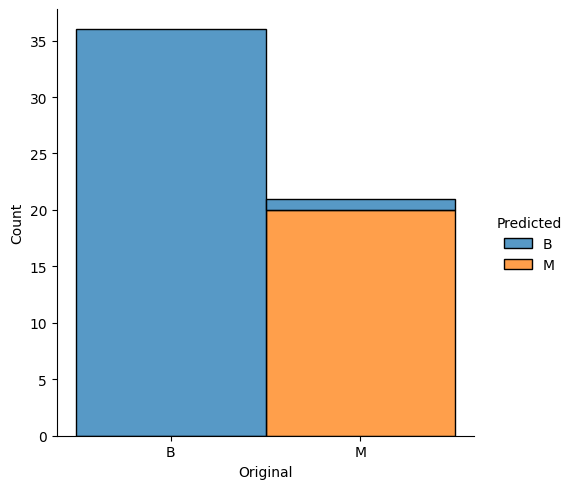

In [88]:
predictions = pd.DataFrame({"Original": y_test, "Predicted": y_pred})
sns.displot(data=predictions, x="Original", hue="Predicted", multiple="stack")